# Neural network capacity and denoising representations for coastal prokaryotic abundance estimation

**Cao Runzhen · 21073359 · OCES 5303 · Assignment 2**

## Scientific motivation and objectives

Coastal microbial abundance varies alongside the physical, chemical and biological conditions of seawater. At the Pivers Island Coastal Observatory (PICO), Ward et al. (2017) examined three years of weekly observations and identified recurring seasonal changes in bacterioplankton community composition. Total prokaryotic abundance quantifies aggregate cell concentration. Estimating this quantity from concurrent environmental measurements tests how much of its variation can be represented by a compact set of covariates.

Direct regression maps the environmental variables to abundance using either a shallow multilayer perceptron (MLP) or a larger residual MLP. Representation learning first compresses the environmental inputs with an autoencoder (AE) or denoising autoencoder (DAE), then estimates abundance with Ridge regression. These approaches impose different learning objectives: the MLP learns abundance directly, whereas the autoencoder learns environmental reconstruction. Linear regression, random forest and principal component analysis (PCA) provide simpler references.

The comparison assesses whether increased capacity improves estimation in later chronological blocks, and whether nonlinear compression or denoising preserves useful abundance information. Repeated initializations and equal-weight ensembles assess the stability of both approaches. A separate scale sensitivity analysis tests whether skewness treatment changes the errors of direct regressors.

## Data and estimation task

The supplied table contains 151 complete observations and 15 columns, with unique sample identifiers and finite numerical values. After chronological sorting, `YearDay` spans 19–1091 with a median sampling interval of seven days. This index supplies temporal order; its calendar origin is not explicitly encoded in the file. The first 120 observations, ending at YearDay 872, form the development period. The remaining 31, YearDay 879–1091, form the historical holdout already examined in Assignment 1 (Figure 1).

The response `Bacteria_abundance` ranges from 1.1404 × $10^6$ to 6.7091 × $10^6$ cells mL$^{-1}$. Archive parameter definitions and overlapping values support interpreting this response as total prokaryotic concentration, including Bacteria, Archaea and *Prochlorococcus* (Johnson and Hunt, 2017). All models use the supplied extract; the external archive supplies measurement definitions.

The ten inputs comprise temperature and salinity; oxygen saturation, pH and dissolved inorganic carbon; chlorophyll *a*; and `NH4`, `NO2.NO3`, `PO4` and `SiO4`. They represent water properties, carbonate chemistry, phytoplankton biomass and nutrient availability (Johnson and Hunt, 2017). Temperature is in °C. The main comparison retains the supplied numerical scales because the scale of `NH4` and the construction and unit of `NO2.NO3` remain unresolved. `SampleID` identifies observations and `YearDay` orders them. The predictor specification retains measured water properties, excludes projected insolation, and excludes `MLLW` because its supplied definition is unresolved. All 151 observations are retained; transformed predictions in the sensitivity analysis are evaluated in the original abundance units.

The mapping is environment at time $t$ to abundance at time $t$. Later-block evaluation therefore requires concurrent environmental measurements; it assesses transfer of an estimation relationship through time.

The first code block loads the [course table](https://raw.githubusercontent.com/julianmak/OCES4303_ML_ocean/refs/heads/main/PIDweekly_env_data.txt) remotely and checks it against the experiment's frozen copy. The notebook metadata stores that copy, source code and results so that the analysis also runs offline. For local execution, save the notebook in the kernel's working directory under the filename below. In Colab, the first cell retrieves the tagged public copy automatically. Figure 1 then places abundance changes alongside the chronological fitting and evaluation windows.

In [1]:
import base64, gzip, json, tempfile, sys
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import display, Image

# Colab downloads the tagged notebook when it is absent from the runtime.
# Default execution reanalyses the stored GPU results and fits four CPU examples.
NOTEBOOK_FILE = Path('ass2_oces5303_21073359.ipynb')
from urllib.request import urlopen
NOTEBOOK_URL = "https://raw.githubusercontent.com/runzhencao/2026_OCES_5303/submission-v2/Assignment_2/ass2_oces5303_21073359.ipynb"
if not NOTEBOOK_FILE.exists():
    with urlopen(NOTEBOOK_URL, timeout=30) as response:
        NOTEBOOK_FILE.write_bytes(response.read())
payload = json.loads(NOTEBOOK_FILE.read_text(encoding="utf-8"))["metadata"]["oces5303"]
archive = json.loads(gzip.decompress(base64.b64decode(payload["archive_b64"])))
workspace = Path(tempfile.mkdtemp(prefix="oces5303_a2_"))
for relative, contents in archive.items():
    destination = workspace / relative
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(contents, encoding="utf-8")
sys.path.insert(0, str(workspace / "code"))
import study_v2 as study
from plot_study_v2 import generate_figures
data_path = workspace / "data/PIDweekly_env_data.txt"
config_path = workspace / "config/experiment_v2.json"
results_root = workspace / "results"
config = json.loads(config_path.read_text())
from urllib.request import urlopen
from urllib.error import URLError
from io import StringIO
DATA_URL = "https://raw.githubusercontent.com/julianmak/OCES4303_ML_ocean/refs/heads/main/PIDweekly_env_data.txt"
try:
    with urlopen(DATA_URL, timeout=15) as response:
        remote_text = response.read().decode("utf-8")
except (URLError, TimeoutError, OSError) as error:
    print("Course download unavailable; using the frozen copy:", type(error).__name__)
else:
    downloaded = pd.read_csv(StringIO(remote_text), sep=r"\s+")
    frozen = pd.read_csv(data_path, sep=r"\s+")
    pd.testing.assert_frame_equal(downloaded, frozen, check_exact=True)
    data_path.write_text(remote_text, encoding="utf-8")
    print("Course table loaded remotely and matched to the frozen experiment data.")
data, X, y = study.load_data(data_path)
assert len(data) == 151 and np.isfinite(X).all() and np.isfinite(y).all()
print(f"{len(data)} observations; {X.shape[1]} inputs; YearDay {data.YearDay.min()}–{data.YearDay.max()}")

Course table loaded remotely and matched to the frozen experiment data.
151 observations; 10 inputs; YearDay 19–1091


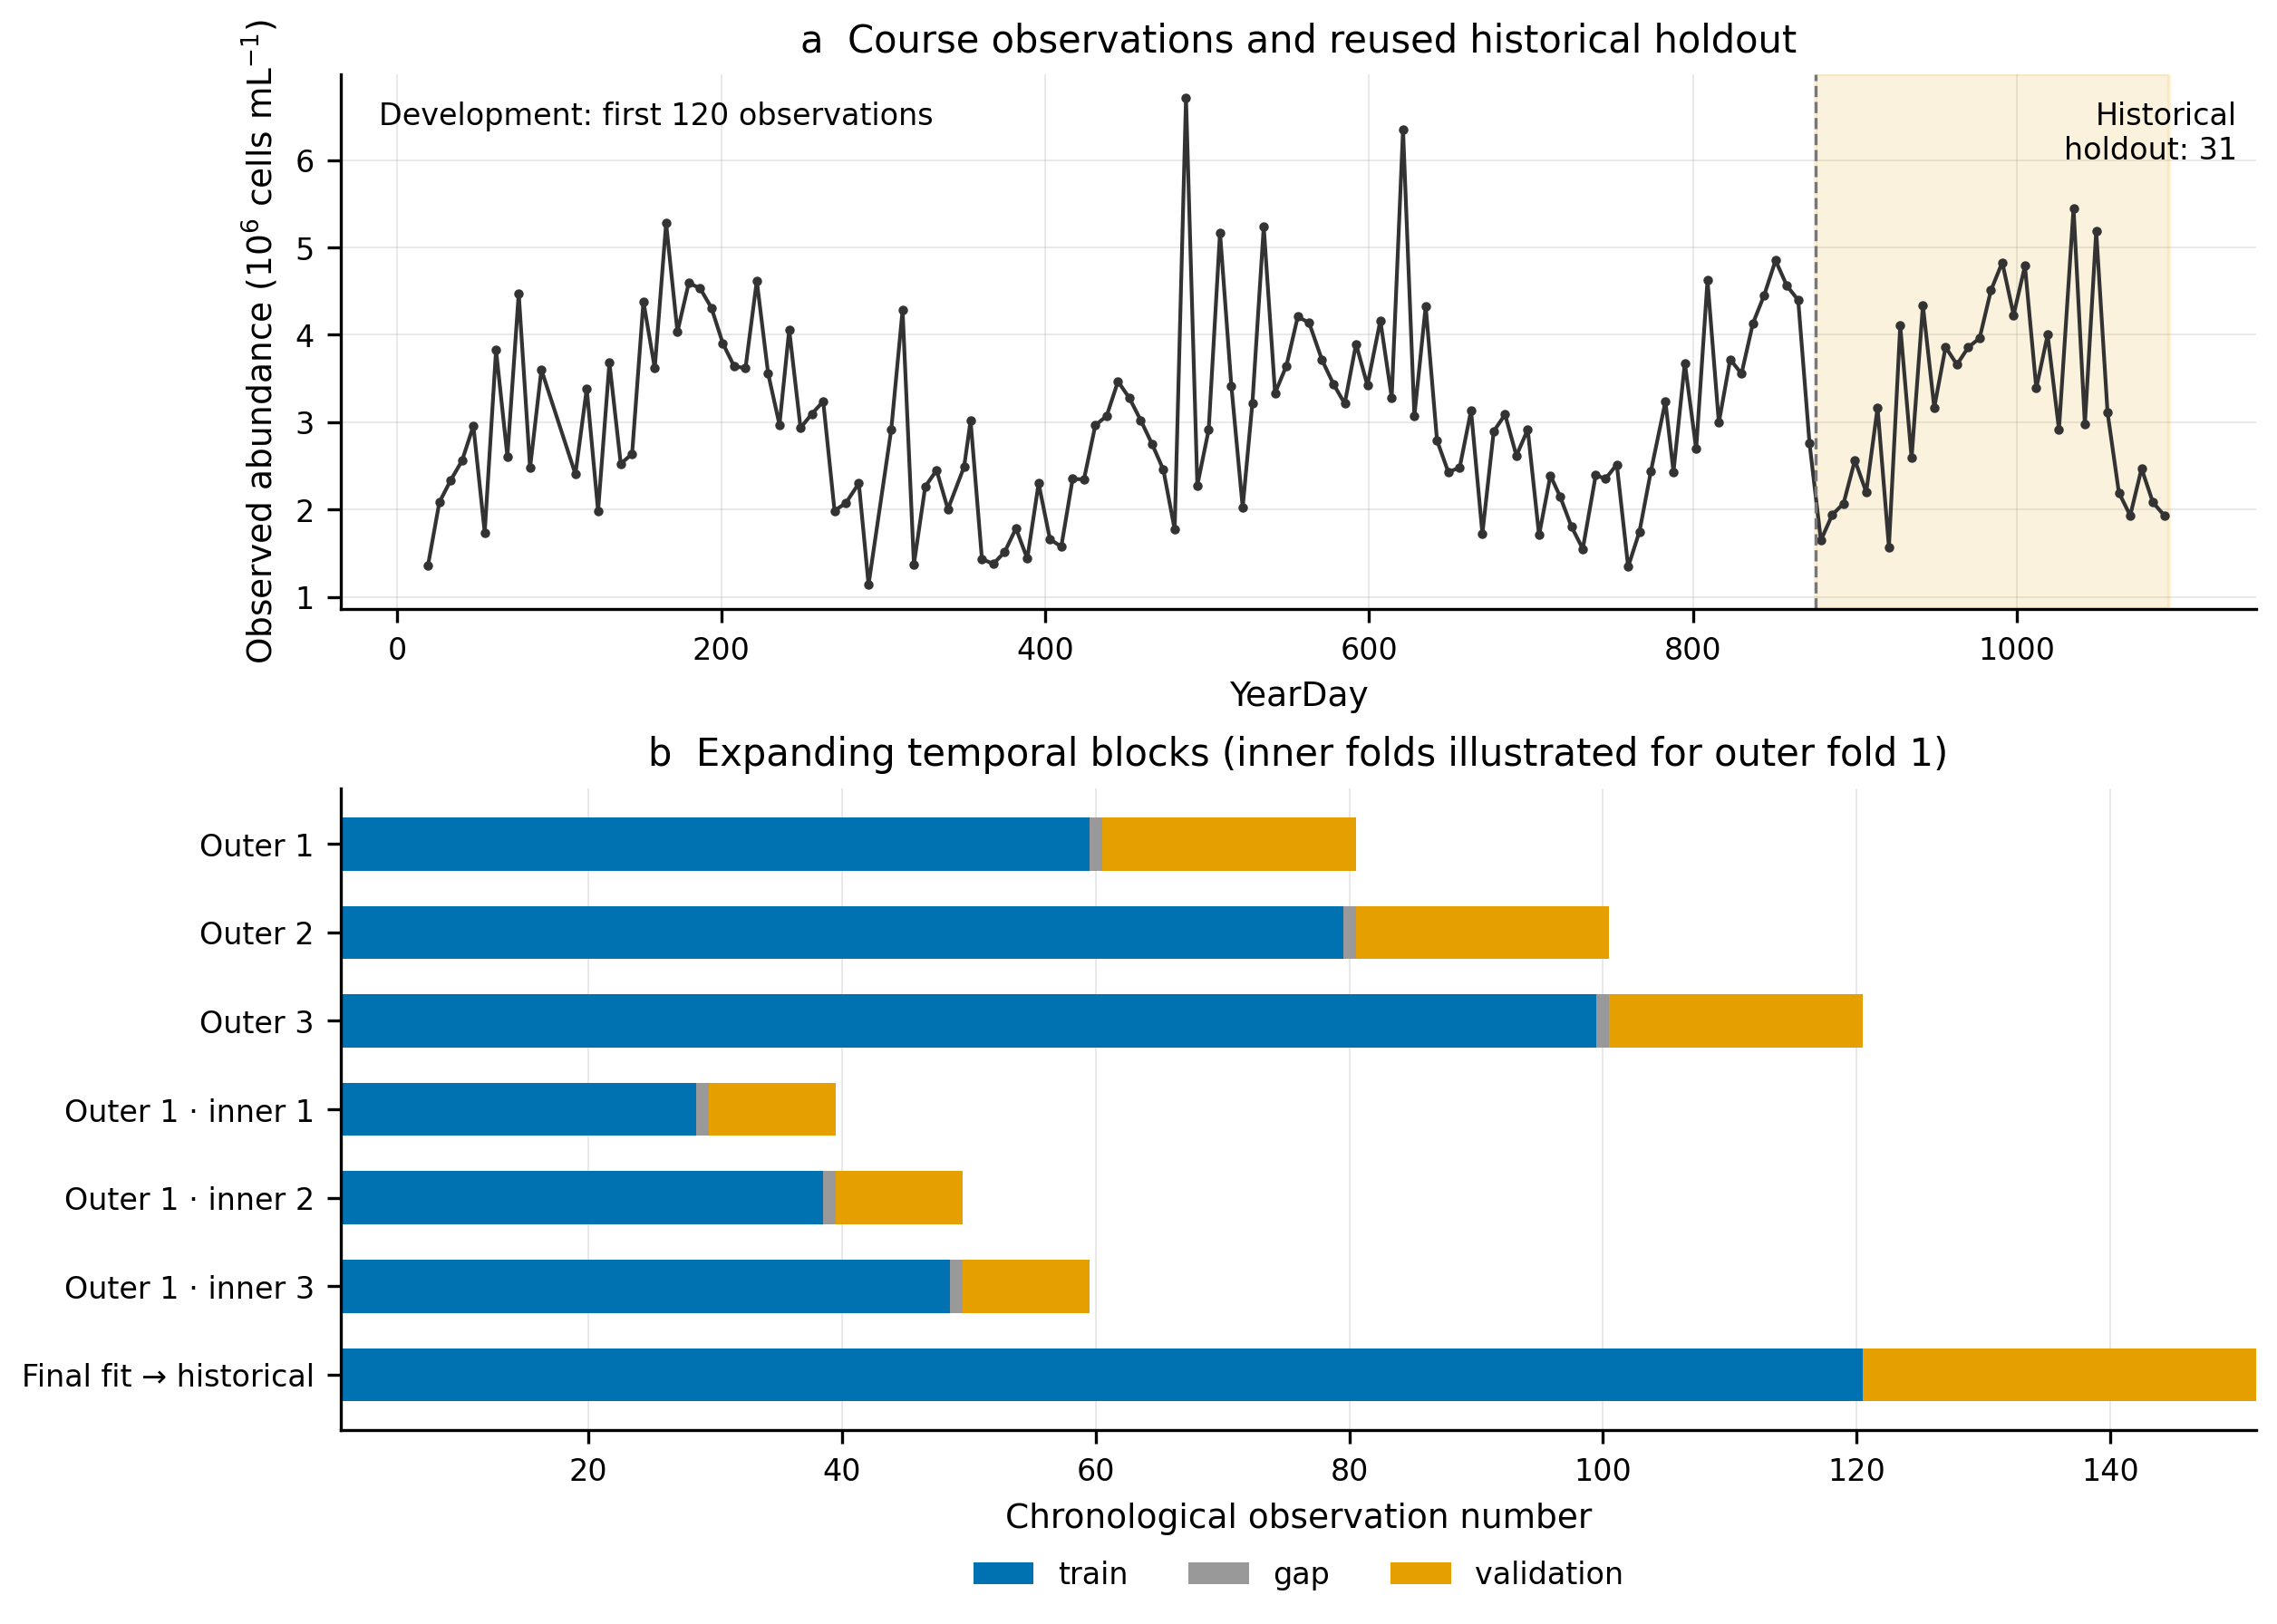

In [2]:
figure_dir = workspace / "figures"
generate_figures(results_root, figure_dir, data_path, config_path)
display(Image(filename=str(figure_dir / "figure_01.png")))

**Figure 1.** Course observations and chronological validation. (a) Total prokaryotic abundance; shading marks the 31-observation historical holdout. (b) Outer fitting, gap and validation membership, with all three inner folds illustrated for outer fold 1. The final fit uses all 120 development observations. Block widths represent observation counts.

## Models and training

### Direct abundance regression

For a standardized input vector $\mathbf{x}^{*}$, both MLPs estimate a standardized target and return predictions to the abundance scale:

$$\widehat y=\mu_y+s_y f_\theta(\mathbf{x}^{*}),\qquad
\mathbf{x}^{*}=(\mathbf{x}-\boldsymbol\mu_x)/\mathbf{s}_x.$$

All means and scales are learned from the current fitting block. Standardization puts inputs with different numerical scales on comparable footing during optimization. The shallow MLP has one Tanh hidden layer with 8, 16 or 32 units, followed by dropout and a linear output. Its 97–385 parameters provide a low-capacity nonlinear reference. The residual MLP projects the ten inputs to width 16, 32 or 64 and applies one or two residual blocks:

$$\mathbf h_{b+1}=\mathbf h_b+0.5\left[W_{b,2}\operatorname{Dropout}\!\left(\tanh(W_{b,1}\mathbf h_b+\mathbf b_{b,1})\right)+\mathbf b_{b,2}\right].$$

A final Tanh and linear layer produce the standardized prediction. This fully connected adaptation uses the shortcut principle of He et al. (2016). Its 737–17,409 parameters provide a joint comparison of increased capacity and residual architecture.

Training minimizes mean squared error with full-batch AdamW in `PyTorch` (PyTorch contributors, n.d.). Each neural family has 12 fixed base configurations. Candidate learning rates are 0.0003, 0.001 and 0.003; weight decay values are 0.0001, 0.001, 0.01 and 0.1; MLP dropout probabilities are 0, 0.1 and 0.2. A sparse set of combinations covers these ranges. Epoch counts of 100, 300 and 800 are selected by inner validation, with checkpoints sharing one training trajectory. Predictions retain the unconstrained linear output.

### Environmental representations followed by Ridge

The AE encodes the standardized inputs into two, four or six latent variables and decodes them to reconstruct all ten inputs. Encoder hidden widths are either [16] or [32, 16], with a symmetric decoder, Tanh hidden activations and linear bottleneck and reconstruction layers. The network has 428–1,968 parameters. Its objective is

$$L_{\mathrm{rec}}=\frac{1}{10n}\sum_{i=1}^{n}\left\|g_\phi(e_\theta(\widetilde{\mathbf{x}}_i^{*}))-\mathbf{x}_i^{*}\right\|_2^2.$$

For the ordinary AE, $\widetilde{\mathbf{x}}^{*}=\mathbf{x}^{*}$. The DAE adds independent Gaussian noise with standard deviation 0.1 to each standardized training input, resampled every epoch, while retaining the clean reconstruction target. This training regularization follows the corrupted-input, clean-target principle of Vincent et al. (2008). Both pipelines receive clean inputs at evaluation.

After reconstruction training, the encoder is frozen. Its latent variables are standardized using the fitting block and supplied to Ridge regression. AE and DAE candidates match in architecture, optimization settings, seeds, epochs and Ridge penalties, differing only in input noise. Reconstruction uses environmental inputs alone; selection of the complete pipeline uses inner abundance RMSE. Compression may retain shared environmental structure while losing low-variance information relevant to abundance, motivating comparison of reconstruction and regression errors.

### Reference models

Five references are the fitting-block mean, temperature-only ordinary least squares, multivariable Ridge, random forest, and PCA followed by Ridge (Table 1). The mean measures improvement over a constant estimate; temperature OLS isolates one physical covariate; Ridge, forest and PCA test linear prediction, nonlinear partitioning and linear compression. Ridge penalties range from 0.01 to 1000 in powers of ten. PCA retains two, four or six components, with the same input and latent standardization used for the autoencoder pipelines. The forest has 400 trees and 12 configurations spanning depth 3 or unrestricted, minimum leaf sizes 2, 5 or 10, and feature fractions 0.7 or 1.0. It retains raw input and target scales.

**Table 1. Fixed model families and search ranges.** Neural parameter counts include weights and biases, but exclude Ridge heads. Every tuned model minimizes mean inner RMSE. All neural families evaluate 100, 300 and 800 epochs; the fixed configurations are a sparse combination of the stated ranges.

| Pipeline | Neural parameters | Candidates or structural range |
|---|---:|---|
| Training mean | — | No tuning |
| Temperature OLS | — | One predictor; no tuning |
| Ridge | — | Six penalties: 0.01–1000 |
| Random forest | — | 12 configurations; 400 trees; depth 3 or unrestricted; leaf size 2, 5, 10; feature fraction 0.7, 1.0 |
| Shallow MLP | 97–385 | 12 configurations; hidden width 8, 16, 32 |
| Residual MLP | 737–17,409 | 12 configurations; width 16, 32, 64; one or two blocks |
| PCA + Ridge | — | 2, 4, 6 components × six penalties |
| AE + Ridge | 428–1,968 | 12 configurations; encoder [16] or [32, 16]; latent dimension 2, 4, 6; six Ridge penalties |
| DAE + Ridge | 428–1,968 | Matched AE configurations; Gaussian input noise $\sigma$ = 0.1 |

The definitions below implement the two direct networks and the common encoder–decoder. The matching AE and DAE architecture lets the later comparison isolate the effect of input corruption.

In [3]:
class ResidualMLP(nn.Module):

    def __init__(self, c):
        super().__init__()
        w = c["width"]
        self.input = nn.Linear(10, w)
        self.blocks = nn.ModuleList(
            [
                nn.Sequential(
                    nn.Linear(w, w),
                    nn.Tanh(),
                    nn.Dropout(c["dropout"]),
                    nn.Linear(w, w),
                )
                for _ in range(c["blocks"])
            ]
        )
        self.output = nn.Linear(w, 1)

    def forward(self, x):
        h = torch.tanh(self.input(x))
        for block in self.blocks:
            h = h + 0.5 * block(h)
        return self.output(torch.tanh(h))


class Autoencoder(nn.Module):

    def __init__(self, c):
        super().__init__()

        def stack(dims):
            layers = []
            for i, (a, b) in enumerate(zip(dims[:-1], dims[1:])):
                layers.append(nn.Linear(a, b))
                if i < len(dims) - 2:
                    layers.append(nn.Tanh())
            return nn.Sequential(*layers)

        self.encoder = stack([10] + c["encoder_hidden"] + [c["latent_dimension"]])
        self.decoder = stack(
            [c["latent_dimension"]] + list(reversed(c["encoder_hidden"])) + [10]
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


def build_model(c):
    if c["family"] == "shallow_mlp":
        return nn.Sequential(
            nn.Linear(10, c["width"]),
            nn.Tanh(),
            nn.Dropout(c["dropout"]),
            nn.Linear(c["width"], 1),
        )
    if c["family"] == "residual_mlp":
        return ResidualMLP(c)
    return Autoencoder(c)

## Chronological validation and performance measures

Three expanding outer folds use 59, 79 and 99 fitting observations, a one-observation gap, and 20 validation observations each. Their validation YearDay ranges are 459–592, 599–732 and 740–872. These are the final three blocks of the earlier five-fold pilot, whose earliest fitting blocks contained 19 and 39 observations. The formal comparison assesses estimation after at least 59 fitting observations.

Within each outer fitting block, three expanding inner folds each reserve ten validation observations and a one-row gap. Inner fitting counts are (28, 38, 48), (48, 58, 68) and (68, 78, 88), respectively. Every scaler, representation and regression model is fitted within the appropriate block. Epoch and hyperparameter selection averages RMSE over three seeds within each inner fold, then over folds. Selected pipelines are refitted from scratch using ten fixed seeds for outer evaluation; deterministic references require one fit.

Final selection repeats the inner procedure within all 120 development observations. The selected configurations are then frozen, refitted and evaluated on the historical holdout.

For observations $y_i$ and predictions $\widehat y_i$, RMSE is $[n^{-1}\sum_i(y_i-\widehat y_i)^2]^{1/2}$, MAE is $n^{-1}\sum_i|y_i-\widehat y_i|$, and $R^2=1-\sum_i(y_i-\widehat y_i)^2/\sum_i(y_i-\bar y)^2$. Negative $R^2$ indicates larger squared error than the evaluated block's observed mean. Errors are reported in $10^6$ cells mL$^{-1}$.

Main outer summaries average seed metrics within folds, then report the three-fold mean and sample standard deviation. Ensemble metrics score the equal-weight mean prediction of ten members. Seed variation measures optimization variability on fixed observations, while fold variation describes performance across the three time blocks.

To verify which settings minimize later-block error, the next code block reconstructs the inner selection scores from individual trial records, averaging seeds before time folds.

In [4]:
# Recompute candidate scores: seeds within folds, then equally weighted folds.
for part in ("formal", "historical_holdout"):
    trials = pd.read_csv(results_root / part / "candidate_scores.csv")
    trials["alpha"] = trials.alpha.fillna(-1)
    keys = ["scope", "family", "candidate_id", "epoch", "alpha"]
    recalculated = trials.groupby(keys + ["inner_fold"]).rmse.mean()
    recalculated = recalculated.groupby(level=keys).mean().rename("recalculated")
    saved = pd.read_csv(results_root / part / "selection_scores.csv")
    merged = saved.set_index(keys).join(recalculated)
    assert merged.recalculated.notna().all()
    assert np.allclose(merged.selection_rmse, merged.recalculated, rtol=1e-10, atol=1e-12)
print("All inner selection scores reproduced from individual trial records.")

All inner selection scores reproduced from individual trial records.


## Results

### Later-block estimation within the development period

Ridge had the lowest mean outer RMSE, 1.009 × $10^6$ cells mL$^{-1}$, followed by random forest (1.021), residual MLP (1.028) and temperature OLS (1.045; Table 2). The shallow MLP averaged 1.120, exceeding Ridge in all three blocks by 0.009, 0.088 and 0.236. Increasing capacity with the residual architecture reduced mean RMSE by 0.091 relative to the shallow network. This improvement occurred in blocks 1 and 3; block 2 instead increased by 0.025 (Figure 2a).

Rankings depended on time. The residual MLP had the smallest mean individual error in block 1 (1.122), close to temperature OLS (1.128), whereas Ridge led blocks 2 and 3 (0.830 and 0.893). Mean outer $R^2$ was 0.076 for the residual MLP and 0.108 for Ridge; this average also reflects differences in response variance among blocks.

AE + Ridge improved on PCA + Ridge by 0.018 in mean RMSE, with fold differences −0.062, +0.056 and −0.049. DAE + Ridge averaged 1.146, compared with 1.135 for AE + Ridge. Denoising slightly reduced error in blocks 1 and 2 but increased it by 0.055 in block 3. Both compression pipelines had higher mean errors than Ridge and random forest.

Initialization mattered most visibly for the residual MLP: its ten seed-specific three-fold mean RMSEs ranged from 0.913 to 1.116 (Figure 2b). Equal-weight ensembling reduced its mean RMSE from 1.028 to 1.019; corresponding reductions were 1.120 to 1.111 for shallow MLP, 1.135 to 1.126 for AE, and 1.146 to 1.136 for DAE. Ensemble gains were modest relative to differences among time blocks. All outer predictions were nonnegative.

**Table 2. Outer chronological validation.** RMSE and MAE use $10^6$ cells mL$^{-1}$. The first three metric columns describe individual models. Metrics are mean ± sample SD across the three outer folds after averaging seed metrics within each fold. The seed-SD column averages the within-fold RMSE SDs; ensemble RMSE averages the three fold-specific ensemble errors.

| Pipeline | RMSE | MAE | $R^2$ | Seed SD | Ensemble RMSE |
|---|---|---|---|---|---|
| Training mean | 1.146 ± 0.160 | 0.874 ± 0.099 | -0.133 ± 0.182 | — | 1.146 |
| Temperature OLS | 1.045 ± 0.146 | 0.768 ± 0.143 | 0.034 ± 0.305 | — | 1.045 |
| Ridge | 1.009 ± 0.257 | 0.750 ± 0.169 | 0.108 ± 0.360 | — | 1.009 |
| Random forest | 1.021 ± 0.194 | 0.713 ± 0.087 | 0.088 ± 0.271 | 0.010 | 1.021 |
| Shallow MLP | 1.120 ± 0.197 | 0.834 ± 0.136 | -0.103 ± 0.327 | 0.051 | 1.111 |
| Residual MLP | 1.028 ± 0.090 | 0.744 ± 0.070 | 0.076 ± 0.144 | 0.071 | 1.019 |
| PCA + Ridge | 1.154 ± 0.189 | 0.894 ± 0.132 | -0.169 ± 0.339 | — | 1.154 |
| AE + Ridge | 1.135 ± 0.128 | 0.844 ± 0.070 | -0.125 ± 0.217 | 0.061 | 1.126 |
| DAE + Ridge | 1.146 ± 0.144 | 0.844 ± 0.093 | -0.154 ± 0.290 | 0.055 | 1.136 |

The next block recomputes abundance errors from individual predictions to check the model comparison. The following figure separates variation across time blocks from variation across initializations.

In [5]:
# Metrics are recomputed from individual predictions, never rounded table entries.
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
for part in ("formal", "historical_holdout"):
    predictions = pd.read_csv(results_root / part / "predictions.csv")
    saved_metrics = pd.read_csv(results_root / part / "metrics.csv")
    rows = []
    for (scope, family, seed), group in predictions.groupby(["scope", "family", "seed"]):
        rows.append({"scope": scope, "family": family, "seed": str(seed),
                     **study.metrics(group.observed, group.predicted)})
    for (scope, family), group in predictions.groupby(["scope", "family"]):
        ensemble = group.groupby("row_index")[["observed", "predicted"]].mean()
        rows.append({"scope": scope, "family": family, "seed": "ensemble",
                     **study.metrics(ensemble.observed, ensemble.predicted)})
    recomputed = pd.DataFrame(rows).set_index(["scope", "family", "seed"])
    saved_metrics["seed"] = saved_metrics.seed.astype(str)
    saved_metrics = saved_metrics.set_index(["scope", "family", "seed"])
    columns = ["rmse", "mae", "r2", "negative_predictions"]
    assert np.allclose(recomputed[columns], saved_metrics.loc[recomputed.index, columns],
                       rtol=1e-10, atol=1e-12)
print("All individual and ensemble metrics reproduced from archived predictions.")

All individual and ensemble metrics reproduced from archived predictions.


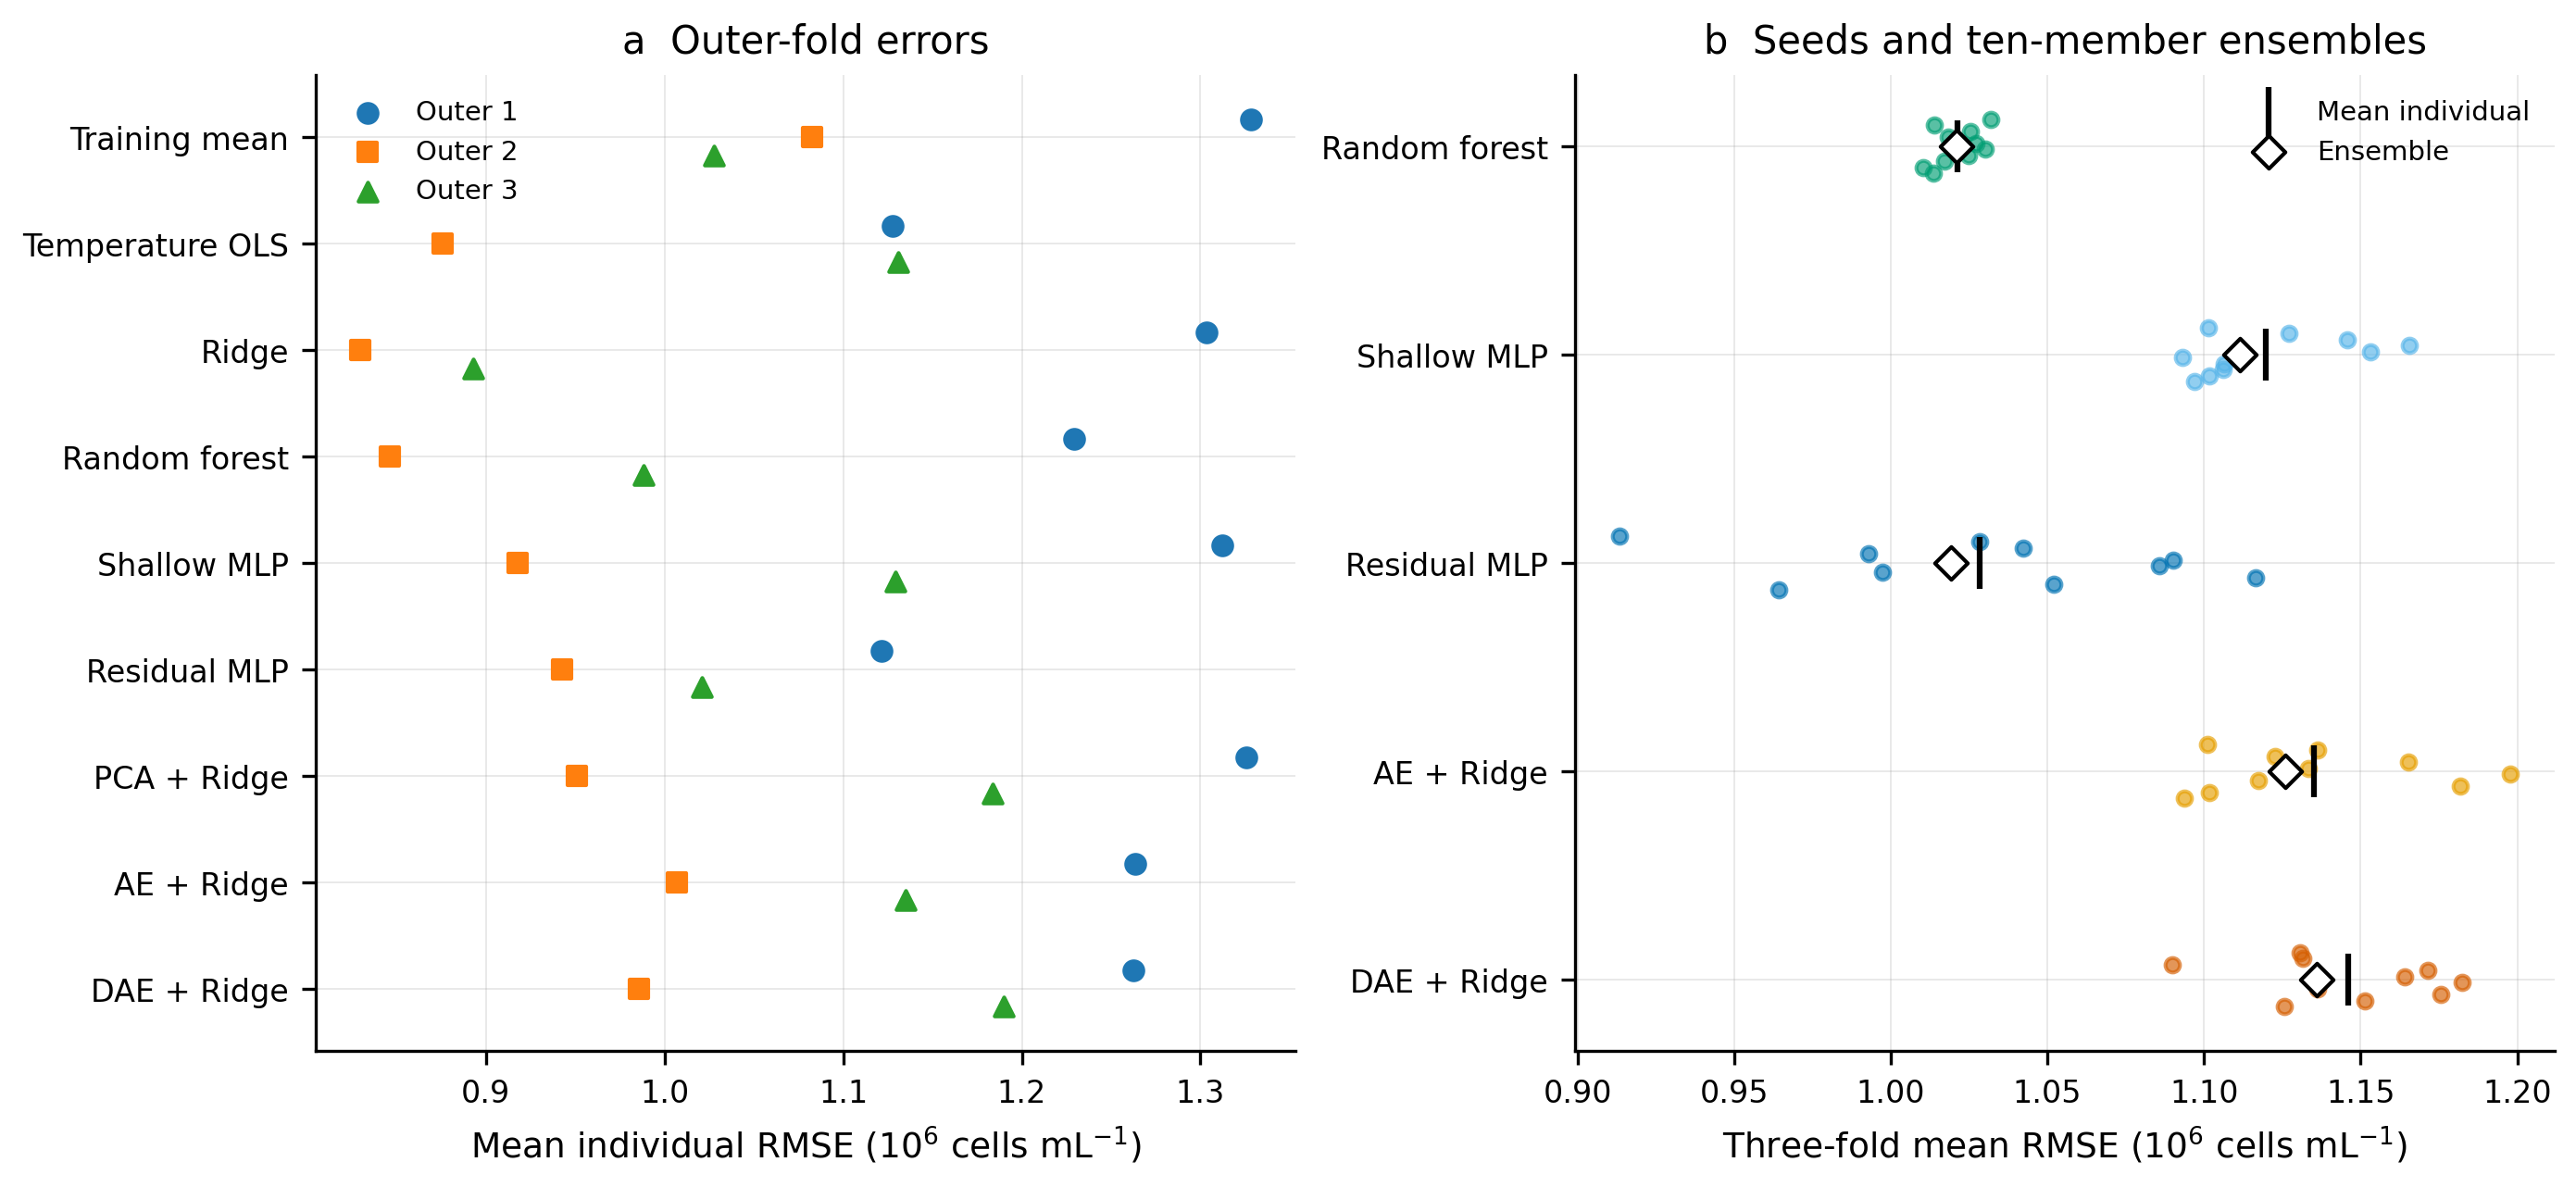

In [6]:
display(Image(filename=str(figure_dir / "figure_02.png")))

**Figure 2.** Outer chronological evaluation. (a) Each point is one outer fold, averaged over ten seeds for stochastic pipelines. (b) Colored dots are individual seeds averaged over the three folds; black ticks mark their mean and open diamonds mark the mean of the three separately evaluated ensemble RMSEs. Each ensemble averages all ten predictions before scoring.

### Capacity, training and compression diagnostics

Final inner selection chose a 193-parameter shallow MLP trained for 800 epochs and a 9,089-parameter residual MLP trained for 300 epochs. For the selected residual base configuration, extending training from 300 to 800 epochs reduced training RMSE from 0.675 to 0.389 but increased validation RMSE from 0.745 to 0.894, indicating overfitting over this interval (Figure 3b). The selected shallow configuration improved both errors across the sampled checkpoints. The chosen residual configuration combined weight decay 0.1 and dropout 0.2. These results favor selecting capacity, regularization and training duration jointly.

Six-dimensional representations gave the best final inner scores for PCA, AE and DAE (Figure 4a). The selected PCA achieved lower validation reconstruction MSE (0.105) than the selected AE (0.127), while its abundance RMSE was higher (0.909 versus 0.854). Reconstruction quality and abundance estimation therefore ranked these representations differently. The selected AE and DAE used the same 560-parameter architecture and 300 epochs, with Ridge penalties of 10 and 1, respectively. In the matched diagnostic at 300 epochs and penalty 10, denoising reduced mean RMSE for seven of twelve base configurations; differences ranged from −0.006 to +0.013 (Figure 4c). The effect of denoising was small and varied across configurations.

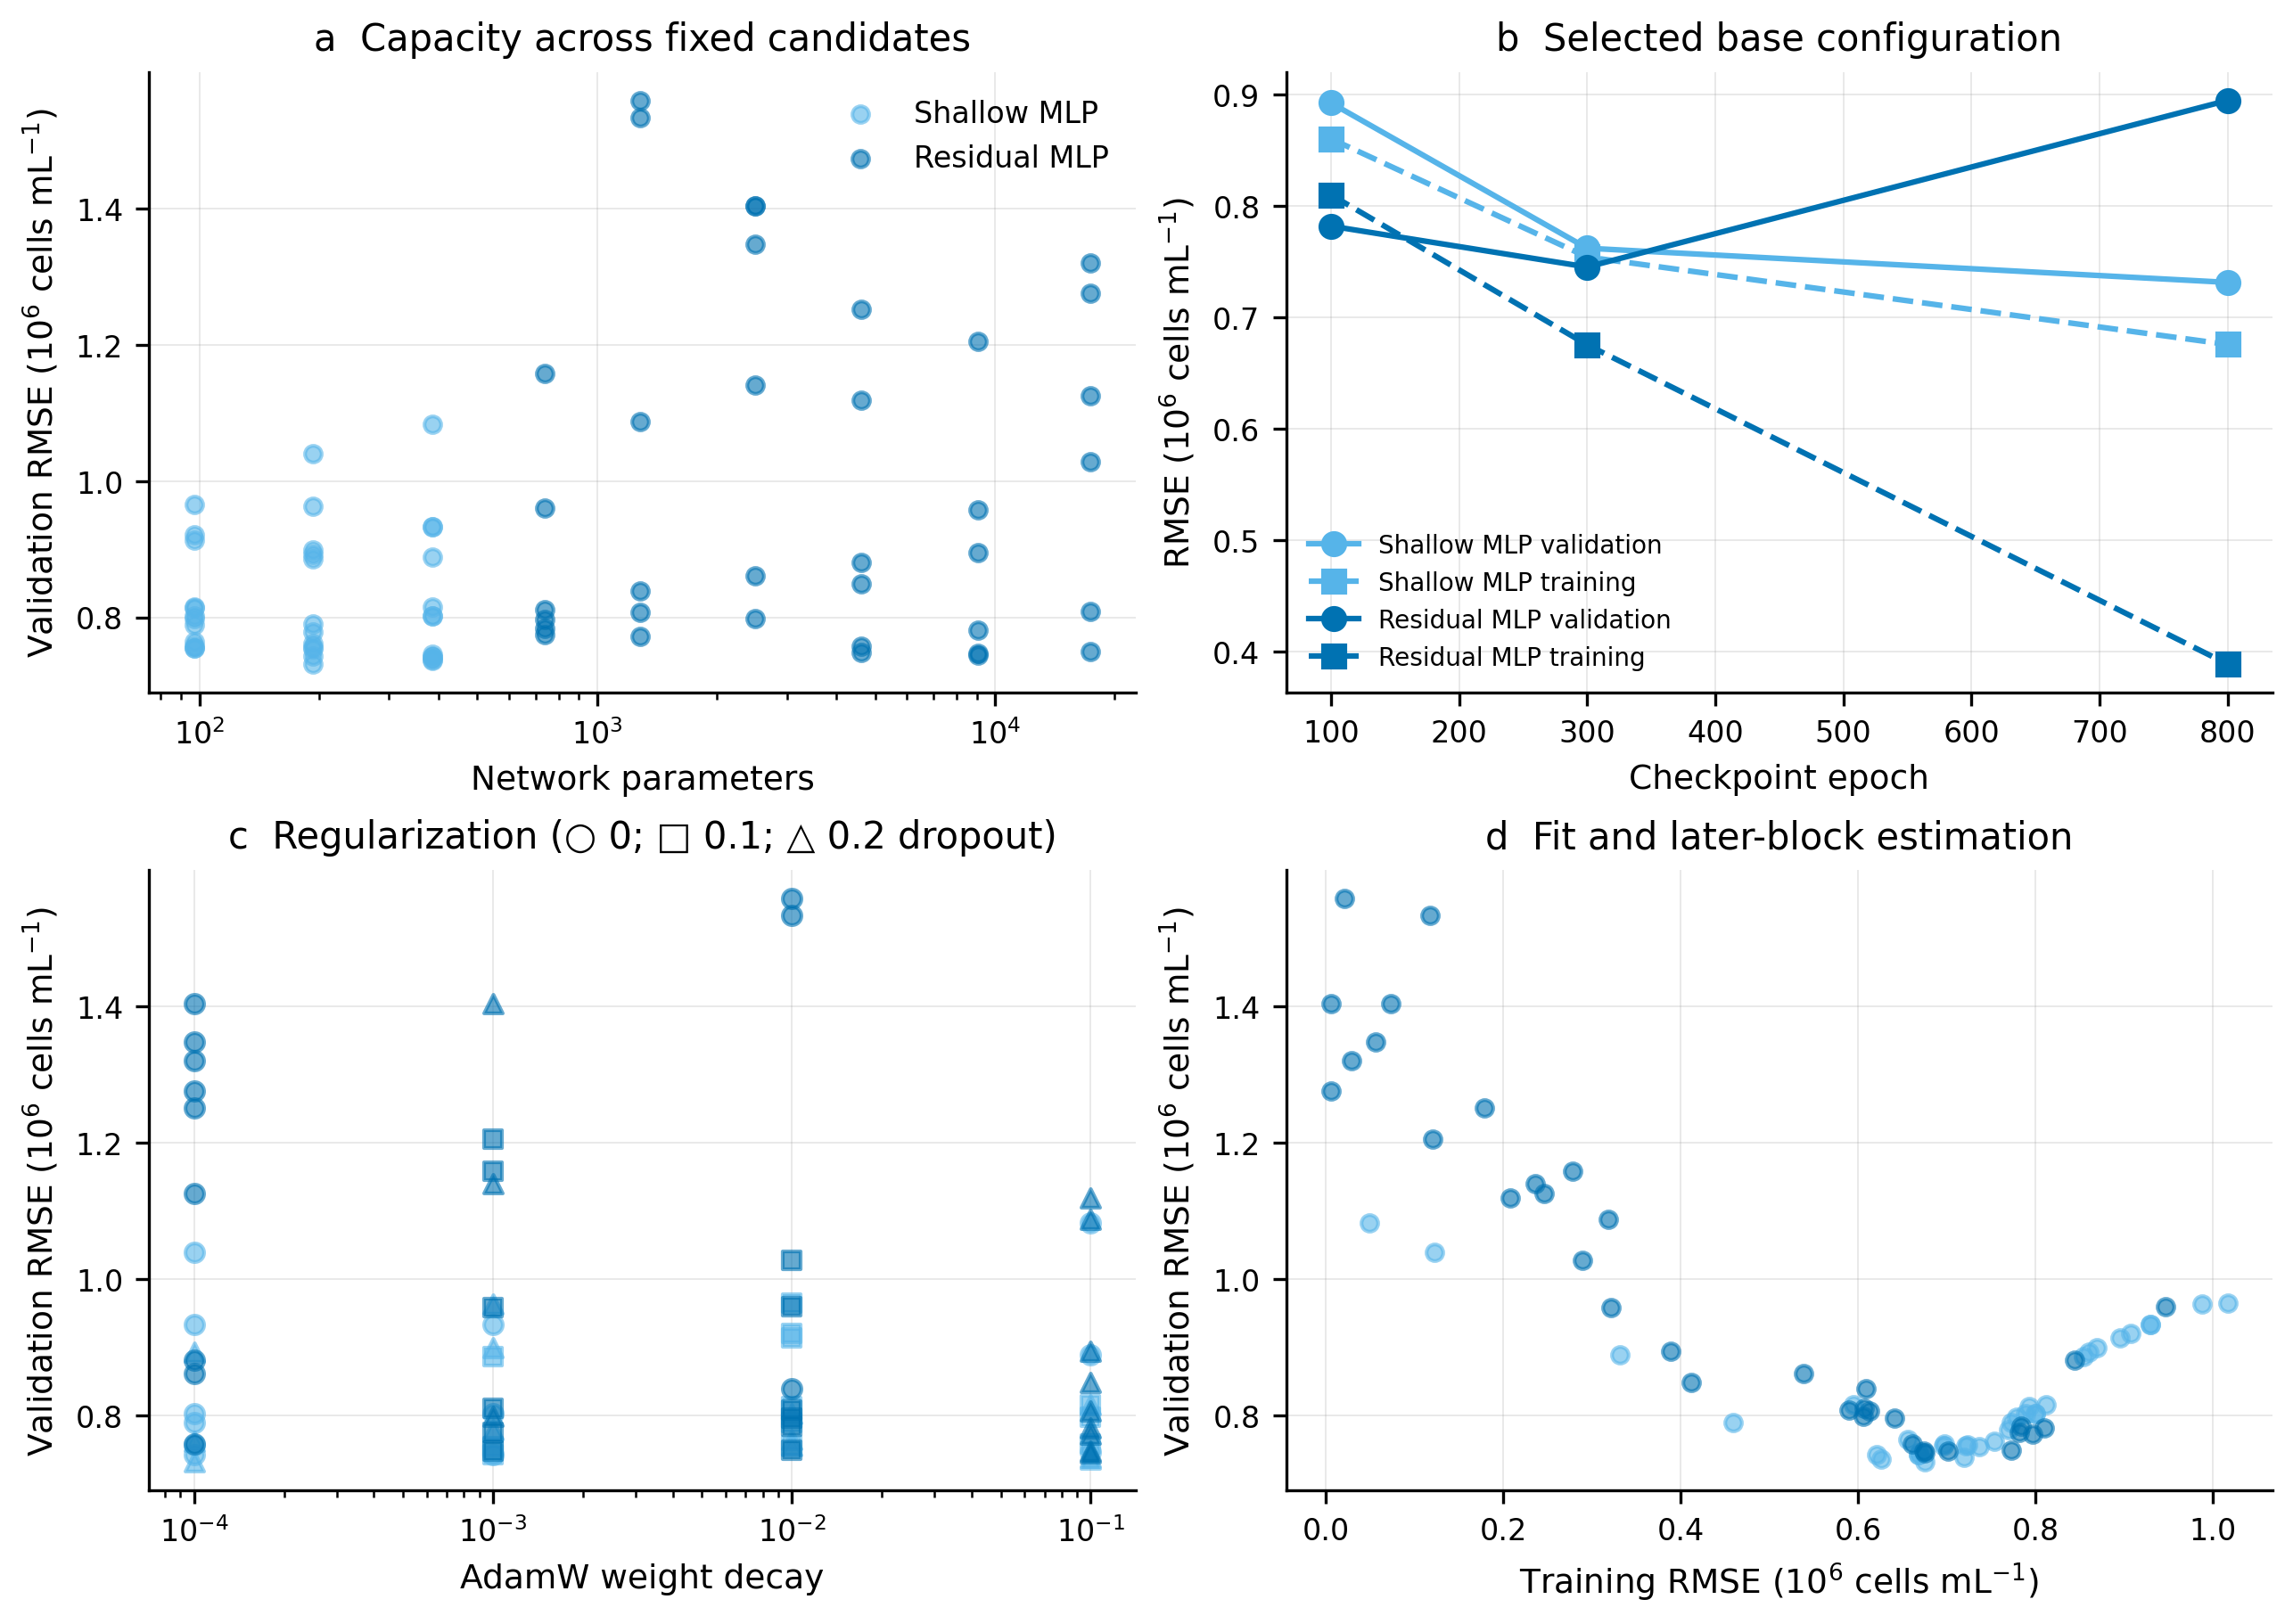

In [7]:
display(Image(filename=str(figure_dir / "figure_03.png")))

**Figure 3.** Inner selection diagnostics within the complete development period. Every plotted score averages three seeds and three inner folds. (a) Fixed candidates and checkpoints by parameter count. (b) Training and validation RMSE at the three checkpoints for each family’s selected base configuration. (c) Weight decay, with marker shape indicating dropout. (d) Training versus validation RMSE. The sparse configurations jointly vary several settings.

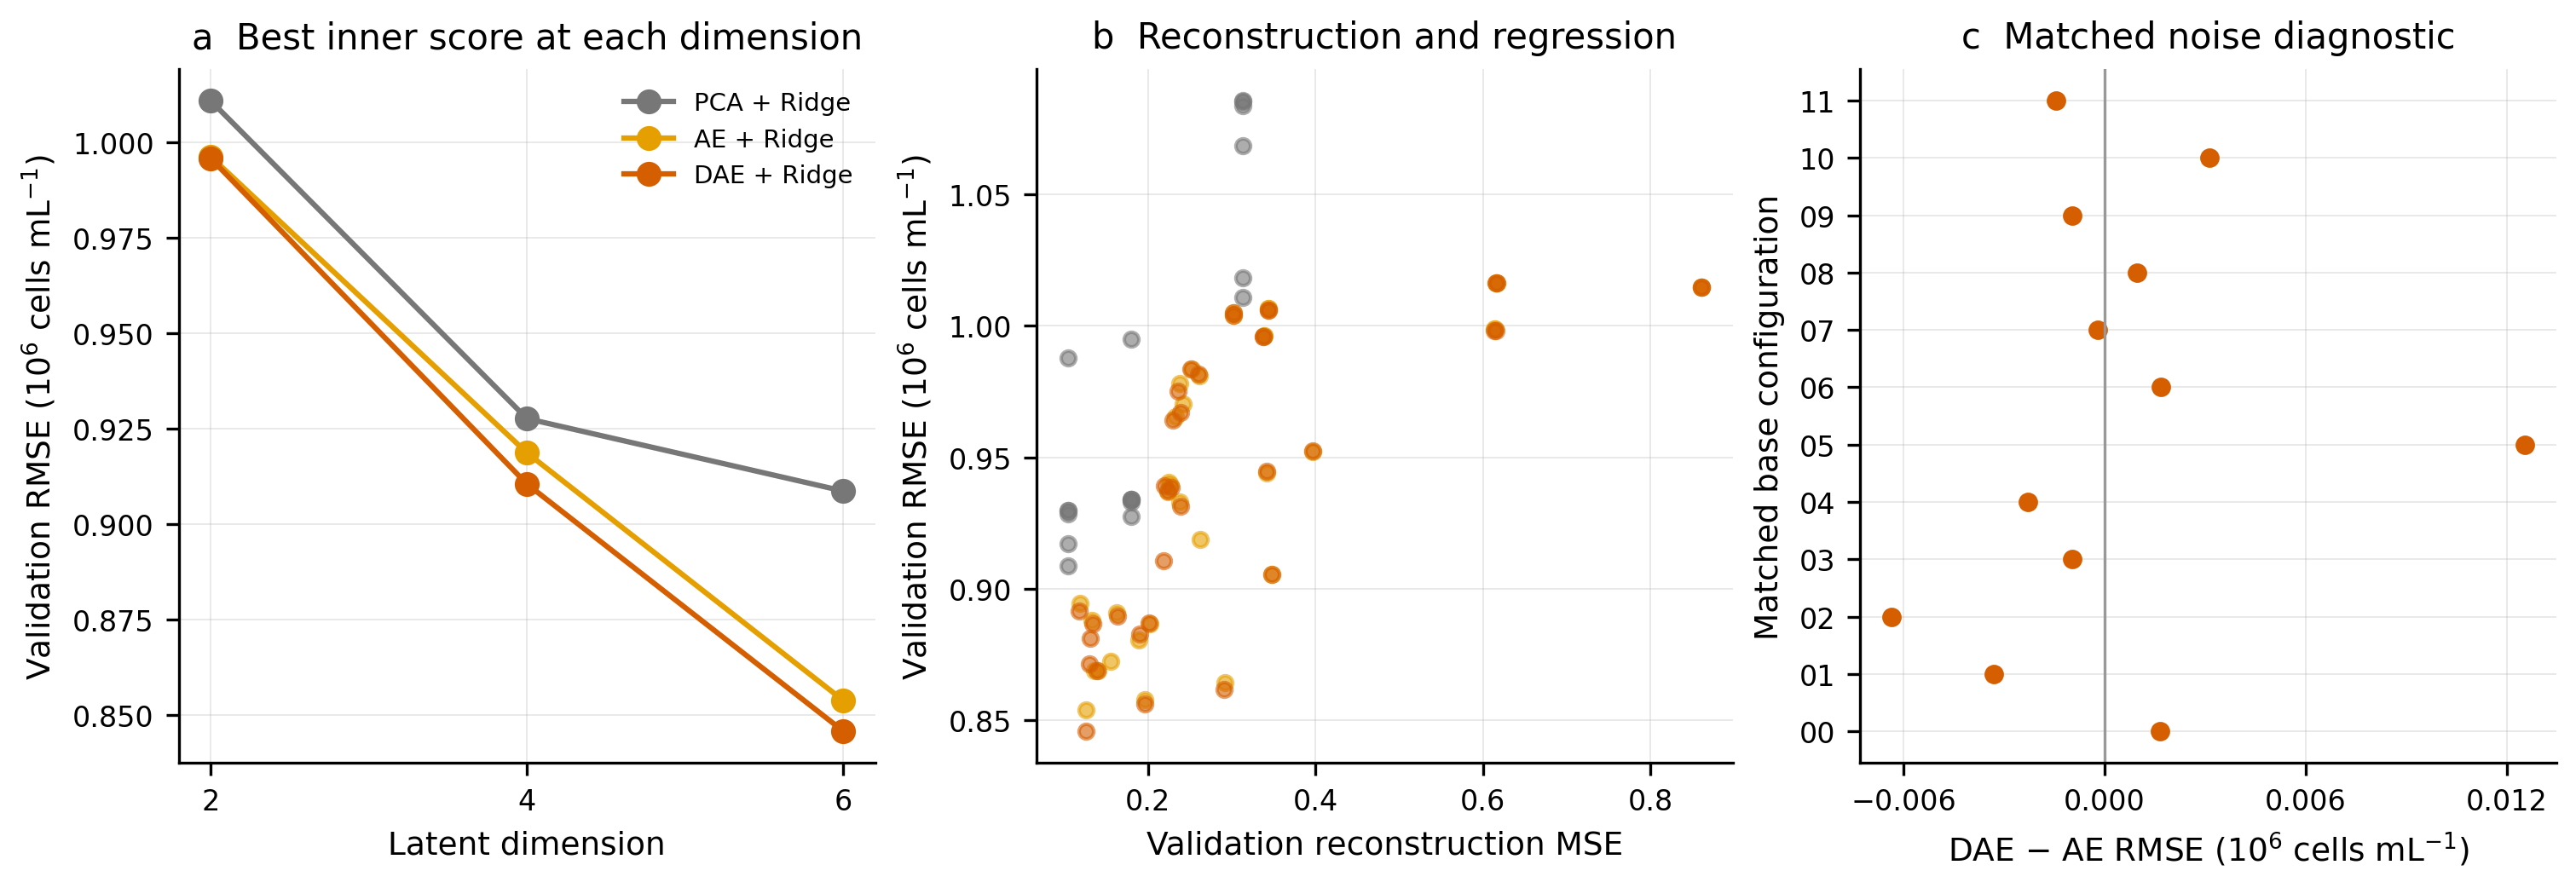

In [8]:
display(Image(filename=str(figure_dir / "figure_04.png")))

**Figure 4.** Compression diagnostics from final inner selection. (a) Lowest mean inner RMSE at each latent dimension, after selection among that dimension’s candidates. (b) Reconstruction error versus regression RMSE; AE and DAE points use the best inner Ridge penalty for each base configuration and checkpoint; PCA points show all dimension-penalty candidates. (c) Paired DAE minus AE RMSE for the twelve matched configurations at the prespecified diagnostic checkpoint of 300 epochs and Ridge alpha 10, averaged over the same three seeds and three folds. Negative differences favor denoising. Reconstruction MSE is dimensionless and measured on clean standardized validation inputs.

### Historical holdout

**Table 3. Historical holdout.** RMSE and MAE use $10^6$ cells mL$^{-1}$. The first three metric columns describe individual models. Individual metrics average ten seeds for stochastic models. Seed SD is the RMSE standard deviation across those ten runs. Ensemble metrics score their equal-weight mean prediction. Deterministic models use one fit.

| Pipeline | RMSE | MAE | $R^2$ | Seed SD | Ensemble RMSE |
|---|---|---|---|---|---|
| Training mean | 1.114 | 0.948 | -0.034 | — | 1.114 |
| Temperature OLS | 1.115 | 0.856 | -0.036 | — | 1.115 |
| Ridge | 1.217 | 0.971 | -0.234 | — | 1.217 |
| Random forest | 1.036 | 0.804 | 0.106 | 0.011 | 1.035 |
| Shallow MLP | 1.077 | 0.823 | 0.033 | 0.027 | 1.074 |
| Residual MLP | 1.096 | 0.844 | -0.002 | 0.044 | 1.089 |
| PCA + Ridge | 0.995 | 0.826 | 0.175 | — | 0.995 |
| AE + Ridge | 0.975 | 0.767 | 0.206 | 0.046 | 0.959 |
| DAE + Ridge | 0.981 | 0.768 | 0.195 | 0.059 | 0.961 |

The final 31 observations changed the ordering (Table 3). AE + Ridge had the lowest mean individual RMSE, 0.975, followed by DAE + Ridge (0.981) and PCA + Ridge (0.995). Shallow and residual MLP errors were 1.077 and 1.096, reversing their average development ranking; Ridge increased to 1.217. The AE and DAE ensembles achieved RMSEs of 0.959 and 0.961, with $R^2$ values of 0.234 and 0.230. All historical predictions were nonnegative.

Figure 5 shows overestimation of several low observations early in the block and underestimation of the peaks at YearDay 1035 and 1049. At YearDay 1035, observed abundance was 5.450, whereas AE and DAE ensemble estimates were 3.100 and 3.114, respectively. Their lower overall RMSE coexisted with substantial errors at individual sampling occasions.

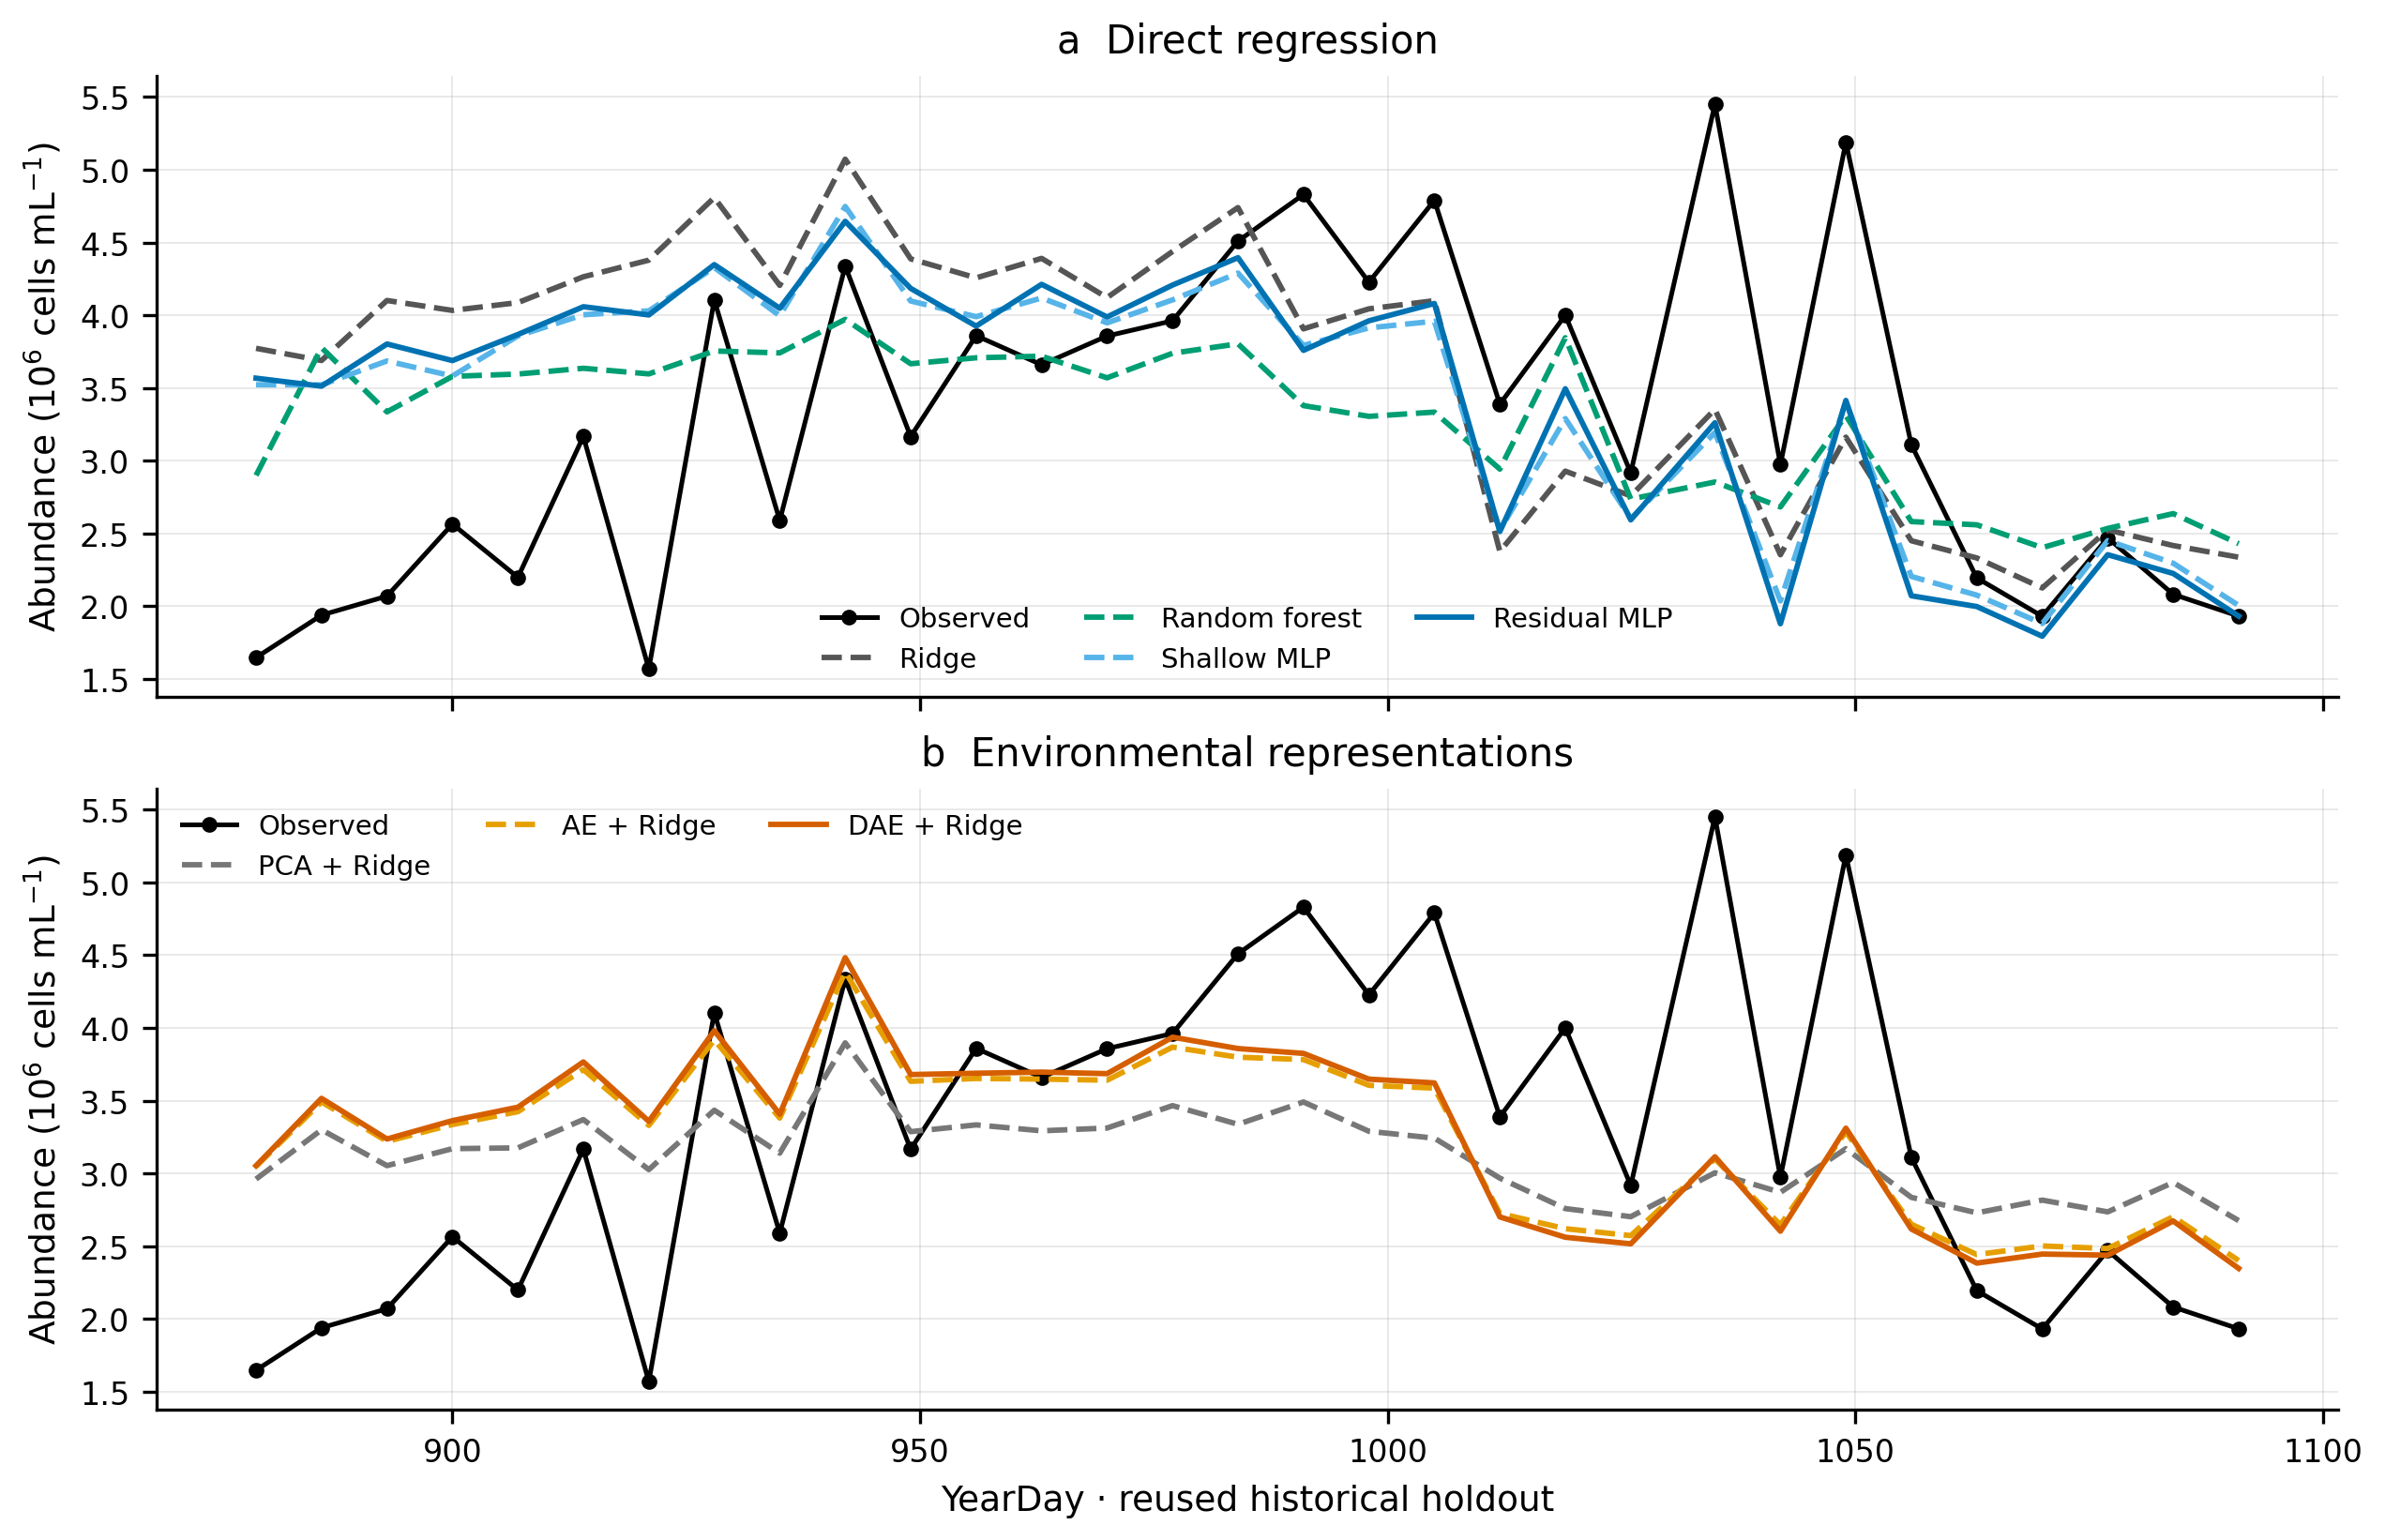

In [9]:
display(Image(filename=str(figure_dir / "figure_05.png")))

**Figure 5.** Predictions on the historical holdout. Panels compare direct regression and environmental representation pipelines against identical observations. Neural and random-forest curves are equal-weight averages of ten members; Ridge and PCA predictions are deterministic. Lines connect contemporaneous estimates across sampling occasions.

### Scale sensitivity

In the 120-observation development period, abundance has sample skewness 0.639, falling to −0.274 after taking its natural logarithm. Standardization preserves skewness. Chlorophyll and four nutrient columns have skewness from 1.214 to 6.265; `NO2.NO3` and `PO4` include 62 and 16 zeros. These distributions motivate a direct test of whether skewness treatment reduces abundance error.

Three treatments compare raw data, a log target, and log inputs with the raw target. The log-target treatment fits $z=\ln(y/y_0)$, where $y_0=10^6$ cells mL$^{-1}$, and predicts $y_0\exp(\widehat z)$. Log inputs apply $\ln(1+x_j/m_j)$ to chlorophyll and the four nutrient columns, where $m_j$ is the positive median in the current fitting block. This dimensionless transform retains zeros and precedes standardization; all other predictors remain unchanged. Log loss gives less weight to large absolute abundance errors. Direct exponentiation estimates a geometric center and does not include an arithmetic-mean bias correction.

The three outer folds, raw-selected hyperparameters, epochs and ten neural seeds are fixed across treatments; Ridge is deterministic. All 189 fits run on CPU, including a fresh raw baseline. This post-hoc analysis tests sensitivity conditional on the selected settings; a new ranking of optimized transformed pipelines would require their own inner searches. The historical holdout is excluded.

**Table 4. Scale sensitivity of direct regressors.** Mean RMSE in $10^6$ cells mL$^{-1}$, averaging seeds within each fold and then the three folds. The code below recomputes the comparison from original-unit predictions.

In [10]:
from scale_sensitivity import summarize
scale_root = results_root / "scale_sensitivity_2026-10-14"
scale_predictions = pd.read_csv(scale_root / "predictions.csv")
scale_metrics, scale_folds, scale_summary = summarize(scale_predictions)
# All values use abundance units; seeds are averaged before the three time folds.
scale_table = scale_summary.pivot(index="family", columns="treatment", values="rmse")
display(scale_table.loc[["ridge", "shallow_mlp", "residual_mlp"],
                        ["raw", "log_target", "log_inputs"]].rename(
    index={"ridge": "Ridge", "shallow_mlp": "Shallow MLP", "residual_mlp": "Residual MLP"},
    columns={"raw": "Raw", "log_target": "Log target", "log_inputs": "Log inputs"}).round(3))

treatment,Raw,Log target,Log inputs
family,,,
Ridge,1.009,1.047,1.010
Shallow MLP,1.116,1.166,1.123
Residual MLP,1.029,1.045,1.023


Logging the target increased mean RMSE for Ridge (1.009 to 1.047), shallow MLP (1.116 to 1.166) and residual MLP (1.029 to 1.045), despite reducing target skewness. Each model improved in the second block and deteriorated in the other two. Logging inputs changed Ridge and shallow MLP mean RMSE to 1.010 and 1.123. Residual MLP RMSE fell slightly to 1.023, while MAE rose from 0.744 to 0.755; its foldwise RMSE differences were −0.044, +0.039 and −0.012. These mixed effects support retaining the original-scale comparison for absolute abundance error and treating transformation choice as a validation question.

## Discussion and limitations

The larger residual MLP improved direct neural estimation in the outer comparison, while Ridge achieved the lowest mean error. The residual MLP's learning curve showed that longer training could reduce fitting error while worsening later-block estimation. At this sample size, model selection must balance capacity, regularization and training duration. The sparse candidate design evaluates combinations of these settings, and the shallow–residual comparison combines changes in parameter count and architecture.

Representation quality depended on the learning objective and evaluation period. PCA reconstructed environmental inputs more accurately than AE, whereas AE achieved lower abundance RMSE in final inner selection. AE and DAE also led the historical comparison but had higher outer errors than the best direct models. These changes in ranking favor evaluating representations by later-block abundance error. Both the matched diagnostic and the separately selected outer results showed inconsistent gains from denoising.

Temperature OLS approaching the best outer errors is consistent with a strong seasonal environmental signal, but its shared seasonality with other predictors limits mechanistic interpretation. Ward et al. (2017) investigated community composition; the present aggregate concentration cannot resolve taxon-specific responses or establish growth and loss rates.

The 151 observations come from one site, with seasonally covarying predictors and potential temporal dependence across the one-observation gaps. Repeated seeds describe optimization variability on this fixed record. The pilot informed the formal design, and Assignment 1 had already examined the historical holdout, making the comparisons exploratory. Unresolved nutrient scales further limit physical interpretation. Evaluation on independent years or sites under a prespecified protocol would strengthen assessment of transfer.

## Conclusion

Across nine pipelines for contemporaneous coastal prokaryotic abundance estimation, Ridge achieved the lowest mean outer RMSE of 1.009 × $10^6$ cells mL$^{-1}$. The residual MLP improved on the shallow MLP, and the AE ensemble led the historical comparison at 0.959 × $10^6$ cells mL$^{-1}$. Denoising gave inconsistent improvements. Model rankings varied across time blocks and between reconstruction and abundance objectives, supporting chronological validation against simple references when selecting neural capacity and representations for this dataset.

## Computation and reproducibility

The formal experiment used two RTX 4090 D GPUs with 24 GB memory each, Python 3.11.15 and PyTorch 2.12.1 with CUDA 12.6. Training used float32, fixed seeds and deterministic settings, with TF32 and mixed precision disabled. Neural trials ran on GPU and reference models on CPU. Search, refitting and evaluation took 916.99 s (15.3 min).

The notebook loads the course data remotely, with a frozen offline copy and the source, configuration and results stored in metadata. Default execution recomputes selection scores, prediction metrics, the scale-sensitivity table and figures, then fits four CPU examples with `PyTorch`. Tables 1–3 describe the archived GPU experiment; Table 4 reports the separate CPU sensitivity experiment. Running every sensitivity treatment on CPU isolates scale changes from device-specific dropout trajectories. The optional full-search mode writes separate results.

[Public repository](https://github.com/runzhencao/2026_OCES_5303) · [Open this report in Colab](https://colab.research.google.com/github/runzhencao/2026_OCES_5303/blob/submission-v2/Assignment_2/ass2_oces5303_21073359.ipynb). Select a Python CPU runtime and **Runtime → Run all**. The default run needs no private files or Drive mount. The public `submission-v2` release contains both assignments, their readable sources and reports. `REPEAT_FULL_STUDY` and `REPEAT_SCALE_CHECK` enable independent training runs; both default to `False`. The final output records the current runtime versions.

**AI assistance:** AI tools assisted analysis design, code preparation, verification, figure preparation, report organization, English revision and Chinese translation.

The four CPU demonstrations use the selected third-outer-fold configurations and seed 5303, with the same standardization and loss functions as the GPU experiment. Their errors are listed separately from the ten-seed GPU results.

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge


def fit_demo(X_train, y_train, X_valid, candidate, seed=5303):
    study.setup(seed)
    sx = StandardScaler().fit(X_train)
    sy = StandardScaler().fit(y_train.reshape(-1, 1))
    xt = torch.tensor(sx.transform(X_train), dtype=torch.float32)
    xv = torch.tensor(sx.transform(X_valid), dtype=torch.float32)
    yt = torch.tensor(sy.transform(y_train.reshape(-1, 1)), dtype=torch.float32)
    model = build_model(candidate)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=candidate['learning_rate'],
        weight_decay=candidate['weight_decay'])
    autoencoder = candidate['family'] in ('ae_ridge', 'dae_ridge')
    noise = candidate.get('noise_std_standardized', 0)
    for epoch in range(candidate['epoch']):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        inputs = xt + noise * torch.randn_like(xt) if noise else xt
        target = xt if autoencoder else yt
        loss = nn.functional.mse_loss(model(inputs), target)
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        if autoencoder:
            z_train = model.encoder(xt).numpy()
            z_valid = model.encoder(xv).numpy()
        else:
            return sy.inverse_transform(model(xv).numpy()).ravel()
    sz = StandardScaler().fit(z_train)
    regressor = Ridge(alpha=candidate['alpha'])
    regressor.fit(sz.transform(z_train), y_train)
    return regressor.predict(sz.transform(z_valid))

In [12]:
selected = json.loads((results_root / "formal/selected_configurations.json").read_text())["outer_3"]
split = json.loads((results_root / "splits.json").read_text())["outer_3"]
train, valid = np.array(split["train"]), np.array(split["validation"])
demo = []
for family in study.NEURAL:
    candidate = selected[family]
    prediction = fit_demo(X[train], y[train], X[valid], candidate)
    demo.append({"family": family, "epoch": candidate["epoch"],
                 "CPU demonstration RMSE": study.metrics(y[valid], prediction)["rmse"]})
display(pd.DataFrame(demo).round(4))

,family,epoch,CPU demonstration RMSE
0,shallow_mlp,100,1.1001
1,residual_mlp,300,0.8245
2,ae_ridge,300,1.0398
3,dae_ridge,100,1.1410


In [13]:
# Optional full replication: 1,888 neural fits and 472 random-forest fits.
# The archived study remains the basis of the fixed narrative and report tables.
REPEAT_FULL_STUDY = False
REPEAT_SCALE_CHECK = False
if REPEAT_SCALE_CHECK:
    from scale_sensitivity import run as run_scale_check
    scale_output = Path(tempfile.mkdtemp(prefix="a2_scale_")) / "results"
    run_scale_check(data_path, results_root, config_path, scale_output)
    print("Independent scale sensitivity experiment saved to", scale_output)
if REPEAT_FULL_STUDY:
    import subprocess
    devices = [f"cuda:{i}" for i in range(torch.cuda.device_count())] or ["cpu"]
    repeat_output = Path(tempfile.mkdtemp(prefix="assignment2_repeat_", dir=Path.cwd()))
    subprocess.run([sys.executable, str(workspace / "code/run_study_v2.py"),
                    "--data", str(data_path), "--config", str(config_path),
                    "--output", str(repeat_output), "--devices", *devices], check=True)
    print("Independent repeated experiment saved to", repeat_output)
original = json.loads((results_root / "environment.json").read_text())
completed = json.loads((results_root / "completion.json").read_text())
print("Archived training:", original["torch"], original["gpu_names"], completed["counts"])
print("Current notebook kernel: PyTorch", torch.__version__, "; demonstrations on CPU")
import platform, sklearn, matplotlib
print("Runtime versions:", json.dumps(dict(python=platform.python_version(),
    numpy=np.__version__, pandas=pd.__version__, sklearn=sklearn.__version__,
    torch=torch.__version__, matplotlib=matplotlib.__version__)))
print("Notebook completed: selection scores, prediction metrics, five figures, scale table and four fresh CPU fits.")

Archived training: 2.12.1+cu126 ['NVIDIA GeForce RTX 4090 D', 'NVIDIA GeForce RTX 4090 D'] {'neural': 1888, 'random_forest': 472}
Current notebook kernel: PyTorch 2.8.0 ; demonstrations on CPU
Runtime versions: {"python": "3.11.6", "numpy": "1.26.4", "pandas": "2.1.4", "sklearn": "1.2.2", "torch": "2.8.0", "matplotlib": "3.8.0"}
Notebook completed: selection scores, prediction metrics, five figures, scale table and four fresh CPU fits.


## References

- Ward, C. S., Yung, C.-M., Davis, K. M., Blinebry, S. K., Williams, T. C., Johnson, Z. I., and Hunt, D. E. (2017). Annual community patterns are driven by seasonal switching between closely related marine bacteria. *The ISME Journal*, 11, 1412–1422. [doi:10.1038/ismej.2017.4](https://doi.org/10.1038/ismej.2017.4).
- Johnson, Z., and Hunt, D. (2017). *Environmental and physical data associated with ocean acidification microbe adaptation from 2012–2014* [Data set]. Biological and Chemical Oceanography Data Management Office (BCO-DMO), version 1, 25 May 2017. [doi:10.1575/1912/bco-dmo.700974.1](https://doi.org/10.1575/1912/bco-dmo.700974.1). Metadata accessed 3 October 2026.
- He, K., Zhang, X., Ren, S., and Sun, J. (2016). Deep residual learning for image recognition. *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition*, 770–778. [Publisher open-access record](https://www.cv-foundation.org/openaccess/content_cvpr_2016/html/He_Deep_Residual_Learning_CVPR_2016_paper.html).
- Vincent, P., Larochelle, H., Bengio, Y., and Manzagol, P.-A. (2008). Extracting and composing robust features with denoising autoencoders. *Proceedings of the 25th International Conference on Machine Learning*, 1096–1103. [doi:10.1145/1390156.1390294](https://doi.org/10.1145/1390156.1390294). [Author-hosted paper](https://www.cs.toronto.edu/~larocheh/publications/icml-2008-denoising-autoencoders.pdf).
- PyTorch contributors (n.d.). *AdamW*. PyTorch 2.12 documentation. [Official documentation](https://docs.pytorch.org/docs/2.12/generated/torch.optim.AdamW.html). Accessed 3 October 2026.